In [1]:
# Cell 1: Load California Housing data and set display options
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Show all columns clearly in notebook outputs
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Load dataset as a pandas DataFrame
dataset = fetch_california_housing(as_frame=True)
housing_df = dataset.frame.copy()

print("Dataset shape:", housing_df.shape)
print("Columns:", list(housing_df.columns))

Dataset shape: (20640, 9)
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [2]:
# Cell 2: Preview rows and descriptive statistics
print("First 5 rows:")
print(housing_df.head())

# Transposed describe() makes feature-wise reading easier
print("\nSummary statistics:")
print(housing_df.describe().T)

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88    -122.23        4.526
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86    -122.22        3.585
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85    -122.24        3.521
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85    -122.25        3.413
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85    -122.25        3.422

Summary statistics:
               count         mean          std         min         25%          50%          75%           max
MedInc       20640.0     3.870671     1.899822    0.499900    2.563400     3.534800     4.743250     15.000100
HouseAge     20640.0    28.639486    12.585558    1.000000   18.000000    29.000000    37.000000     52.000000
AveRooms     20640.0     5.429000     2.474173    

In [3]:
# Cell 3: Quick data quality checks
print("Missing values per column:")
print(housing_df.isna().sum())

# Duplicate count helps detect repeated records
duplicate_count = housing_df.duplicated().sum()
print("\nDuplicate rows:", duplicate_count)

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows: 0


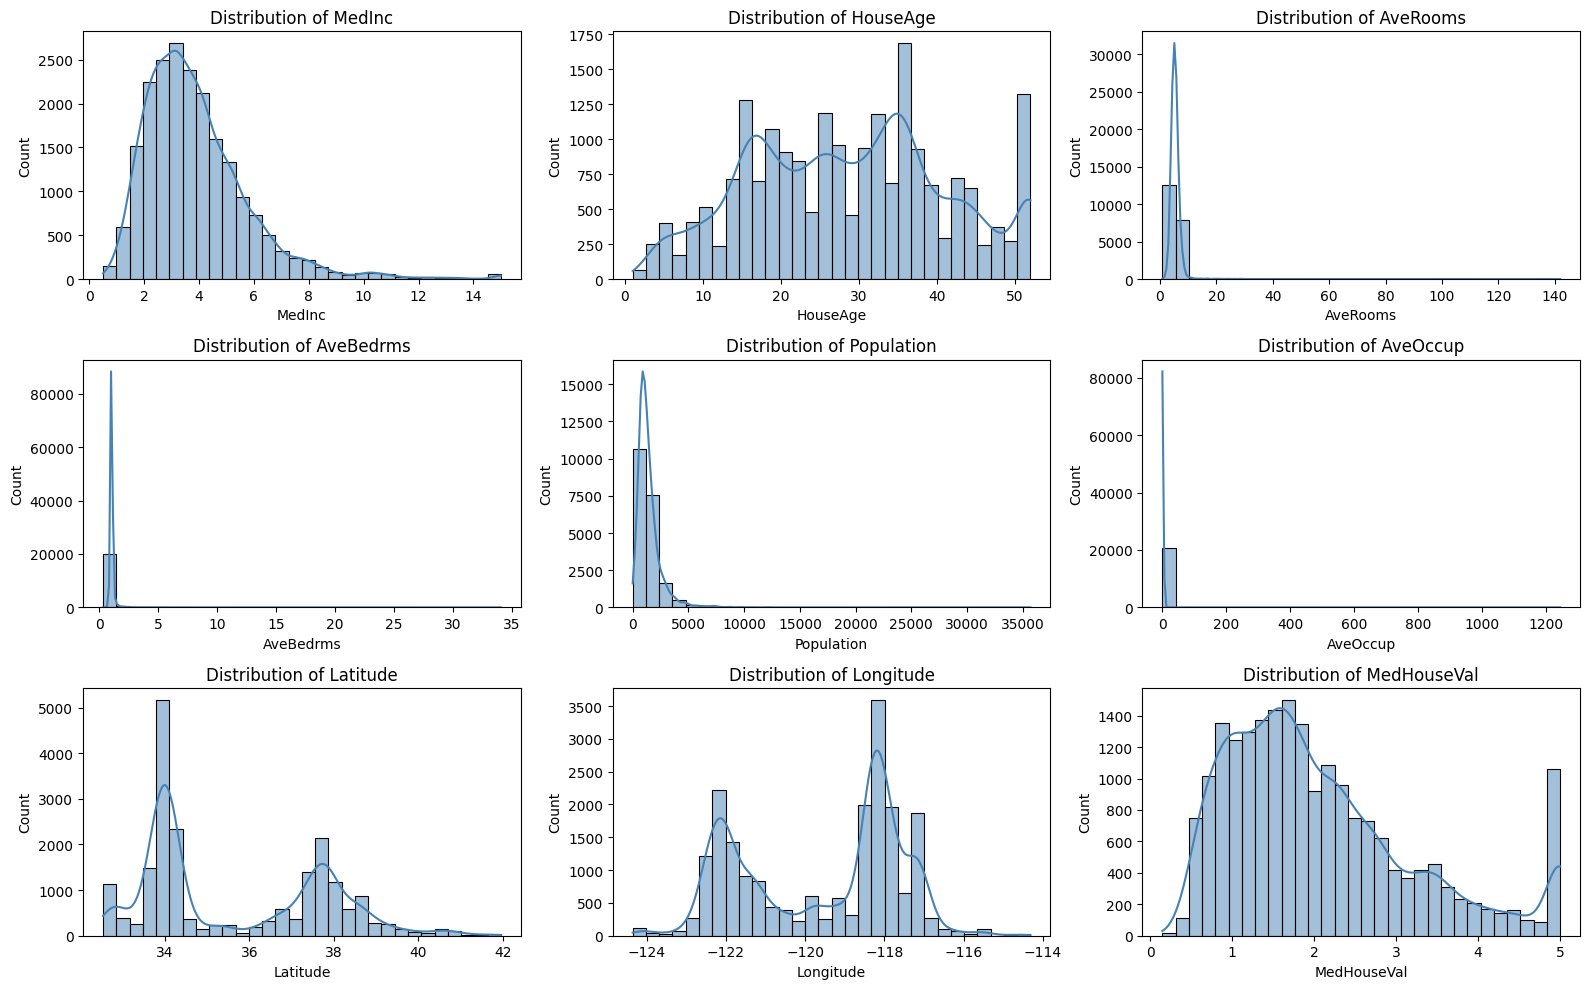

In [4]:
# Cell 4: Plot feature distributions with histograms
plt.figure(figsize=(16, 10))
for i, feature in enumerate(housing_df.columns, start=1):
    plt.subplot(3, 3, i)
    sns.histplot(housing_df[feature], kde=True, bins=30, color="steelblue")
    plt.title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

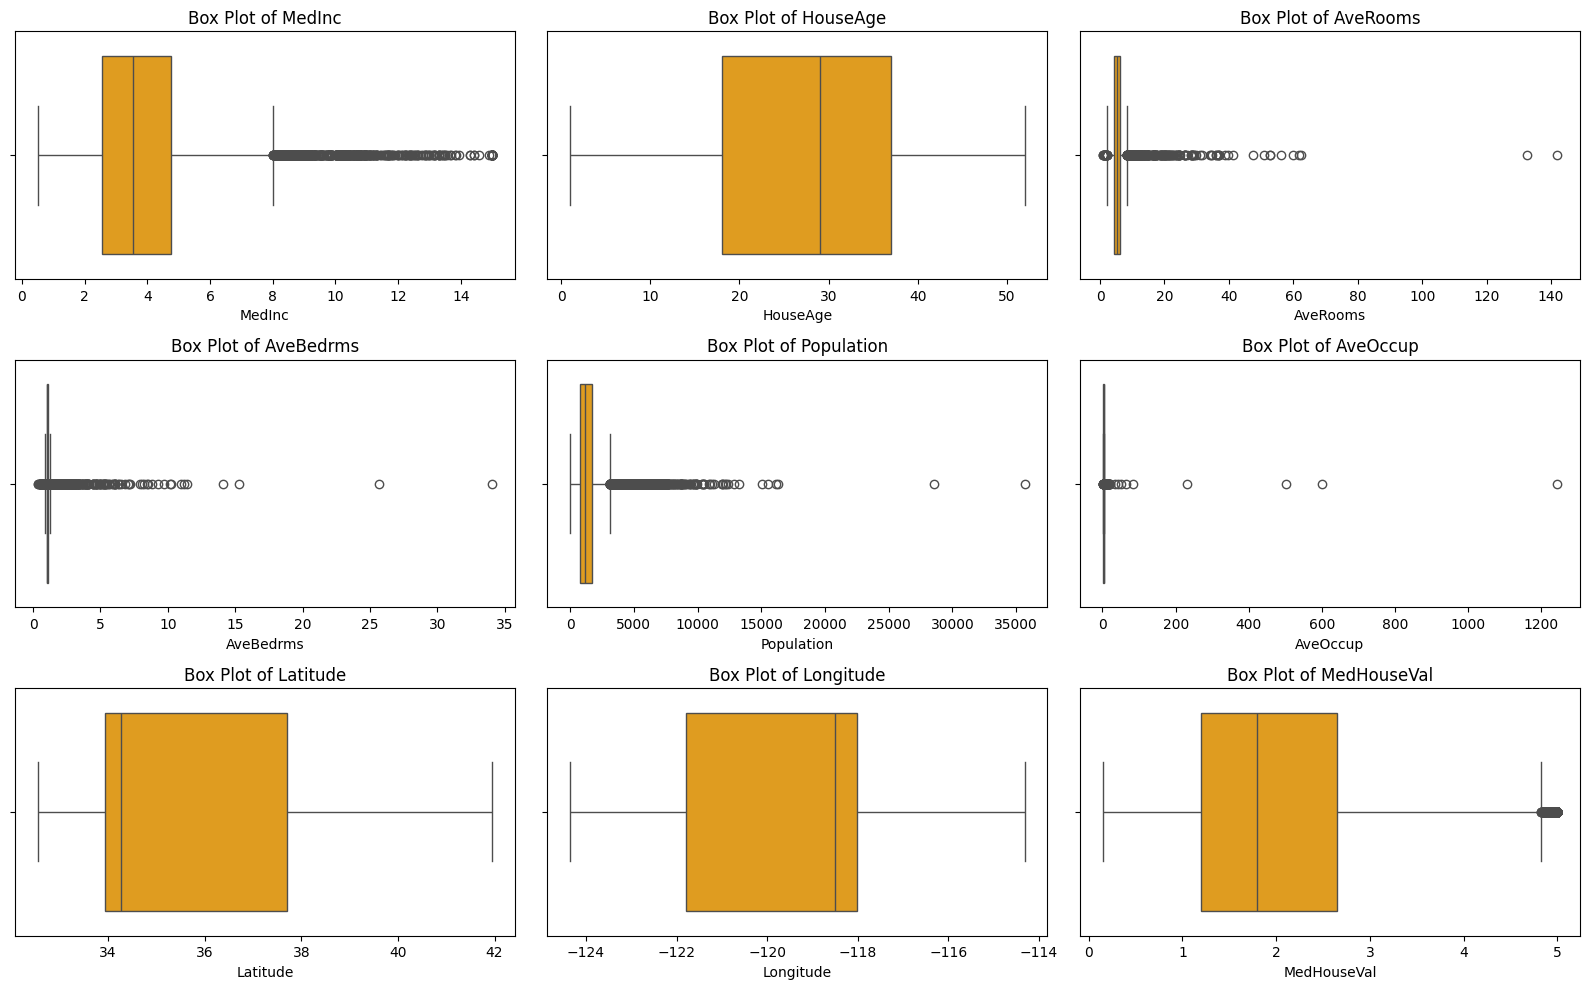

In [5]:
# Cell 5: Box plots to visualize spread and potential outliers
plt.figure(figsize=(16, 10))
for i, feature in enumerate(housing_df.columns, start=1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=housing_df[feature], color="orange")
    plt.title(f"Box Plot of {feature}")

plt.tight_layout()
plt.show()

In [6]:
# Cell 6: Build IQR-based outlier report for each feature
outlier_report = []
for feature in housing_df.columns:
    q1 = housing_df[feature].quantile(0.25)
    q3 = housing_df[feature].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    # Count values outside the IQR bounds
    outlier_count = ((housing_df[feature] < lower) | (housing_df[feature] > upper)).sum()
    outlier_report.append((feature, int(outlier_count), round(lower, 3), round(upper, 3)))

outlier_df = pd.DataFrame(outlier_report, columns=["feature", "outlier_count", "lower_bound", "upper_bound"])
print(outlier_df.sort_values("outlier_count", ascending=False).reset_index(drop=True))

       feature  outlier_count  lower_bound  upper_bound
0    AveBedrms           1424        0.866        1.240
1   Population           1196     -620.000     3132.000
2  MedHouseVal           1071       -0.981        4.824
3     AveOccup            711        1.151        4.561
4       MedInc            681       -0.706        8.013
5     AveRooms            511        2.023        8.470
6     HouseAge              0      -10.500       65.500
7     Latitude              0       28.260       43.380
8    Longitude              0     -127.485     -112.325
